# Mumbai & Navi Mumbai AQI (2015–2020): Coordinate Integration + ML

This notebook uses the classic Kaggle **Air Quality Data in India (2015–2020)** files `station_day.csv` and `stations.csv`, plus the accompanying external station-coordinate file `station_coordinates_external.csv`.

**Important finding from the supplied files:** `stations.csv` has 13 Mumbai/Navi Mumbai station metadata rows, but `station_day.csv` has daily observations for the 10 Mumbai station IDs and **zero observations for the three Navi Mumbai station IDs (MH017, MH018, MH019)**. Adding coordinates does not create historical measurements. The notebook will report this clearly and will not invent Navi Mumbai observations.

Coordinates in the external file are mixed provenance: several are published station coordinates; others are approximate locality coordinates and marked as such. For a graded spatial analysis, verify approximate points against official MPCB coordinates or station addresses before presenting them as exact locations.

The ML target is the observed `AQI`; predictors are pollutant measurements. This is same-day AQI estimation, not future AQI forecasting.

## 1. Install and import libraries

In [28]:
# If needed, run once:
# %pip install pandas numpy matplotlib seaborn scikit-learn

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

DATA_DIR = Path(".")  # Change this if files are stored elsewhere
OUTPUT_DIR = Path("aqi_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

STATION_DAY_FILE = DATA_DIR / "station_day.csv"
STATIONS_FILE = DATA_DIR / "stations.csv"
COORDINATES_FILE = DATA_DIR / "station_coordinates_external.csv"

for file in [STATION_DAY_FILE, STATIONS_FILE, COORDINATES_FILE]:
    print(file, "exists:", file.exists())
    if not file.exists():
        raise FileNotFoundError(f"Missing {file}. Place all three CSVs beside this notebook or update DATA_DIR.")


station_day.csv exists: True
stations.csv exists: True
station_coordinates_external.csv exists: True


## 2. Load the Kaggle files and external coordinate file

In [29]:
daily_raw = pd.read_csv(STATION_DAY_FILE)
stations_raw = pd.read_csv(STATIONS_FILE)
coords_raw = pd.read_csv(COORDINATES_FILE)

print("station_day:", daily_raw.shape)
print("stations:", stations_raw.shape)
print("external coordinates:", coords_raw.shape)

print("\nStation-day columns:", daily_raw.columns.tolist())
print("Station metadata columns:", stations_raw.columns.tolist())
print("Coordinate columns:", coords_raw.columns.tolist())

display(daily_raw.head())
display(stations_raw[stations_raw["City"].astype(str).str.contains("Mumbai", case=False, na=False)])
display(coords_raw)


station_day: (108035, 16)
stations: (230, 5)
external coordinates: (13, 7)

Station-day columns: ['StationId', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
Station metadata columns: ['StationId', 'StationName', 'City', 'State', 'Status']
Coordinate columns: ['StationId', 'StationName', 'City', 'Latitude', 'Longitude', 'Coordinate_Notes', 'Coordinate_Source_Type']


,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,0.10,NaN,NaN
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,0.06,184.0,Moderate
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,0.08,197.0,Moderate
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,0.12,198.0,Moderate
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,0.07,188.0,Moderate


,StationId,StationName,City,State,Status
139,MH005,"Bandra, Mumbai - MPCB",Mumbai,Maharashtra,Active
140,MH006,"Borivali East, Mumbai - MPCB",Mumbai,Maharashtra,Active
141,MH007,"Chhatrapati Shivaji Intl. Airport (T2), Mumbai...",Mumbai,Maharashtra,Active
142,MH008,"Colaba, Mumbai - MPCB",Mumbai,Maharashtra,Active
143,MH009,"Kurla, Mumbai - MPCB",Mumbai,Maharashtra,Active
144,MH010,"Powai, Mumbai - MPCB",Mumbai,Maharashtra,Active
145,MH011,"Sion, Mumbai - MPCB",Mumbai,Maharashtra,Active
146,MH012,"Vasai West, Mumbai - MPCB",Mumbai,Maharashtra,Active
147,MH013,"Vile Parle West, Mumbai - MPCB",Mumbai,Maharashtra,Active
148,MH014,"Worli, Mumbai - MPCB",Mumbai,Maharashtra,Active


,StationId,StationName,City,Latitude,Longitude,Coordinate_Notes,Coordinate_Source_Type
0,MH005,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,Published coordinates for Bandra CAAQMS; match...,MPCB report coordinates
1,MH006,"Borivali East, Mumbai - MPCB",Mumbai,19.245600,72.865100,Approximate locality coordinate; verify exact ...,Approximate locality
2,MH007,"Chhatrapati Shivaji Intl. Airport (T2), Mumbai...",Mumbai,19.100400,72.876300,Published Airport CAAQMS coordinates; matched ...,MPCB report coordinates
3,MH008,"Colaba, Mumbai - MPCB",Mumbai,18.907800,72.819700,Published Colaba CAAQMS coordinates; matched b...,MPCB report coordinates
4,MH009,"Kurla, Mumbai - MPCB",Mumbai,19.086300,72.888800,Published Kurla CAAQMS coordinates; matched by...,MPCB report coordinates
5,MH010,"Powai, Mumbai - MPCB",Mumbai,19.133400,72.913200,Published Powai CAAQMS coordinates; matched by...,MPCB report coordinates
6,MH011,"Sion, Mumbai - MPCB",Mumbai,19.035528,72.859755,Published Sion CAAQMS coordinates; matched by ...,MPCB report coordinates
7,MH012,"Vasai West, Mumbai - MPCB",Mumbai,19.371000,72.812000,Approximate Vasai West locality coordinate; st...,Approximate locality
8,MH013,"Vile Parle West, Mumbai - MPCB",Mumbai,19.109500,72.835300,Published Vile Parle CAAQMS coordinates; match...,MPCB report coordinates
9,MH014,"Worli, Mumbai - MPCB",Mumbai,18.993600,72.812800,Published station coordinate from station-spec...,Published secondary source


## 3. Standardize names and validate coordinate data

In [30]:
def standardize_columns(df):
    out = df.copy()
    out.columns = (
        out.columns.astype(str).str.strip().str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return out

daily = standardize_columns(daily_raw)
stations = standardize_columns(stations_raw)
coords = standardize_columns(coords_raw)

required_daily = {"stationid", "date", "aqi"}
required_stations = {"stationid", "stationname", "city", "state"}
required_coords = {"stationid", "latitude", "longitude"}

if not required_daily.issubset(daily.columns):
    raise ValueError(f"station_day.csv missing columns: {required_daily - set(daily.columns)}")
if not required_stations.issubset(stations.columns):
    raise ValueError(f"stations.csv missing columns: {required_stations - set(stations.columns)}")
if not required_coords.issubset(coords.columns):
    raise ValueError(f"Coordinate CSV missing columns: {required_coords - set(coords.columns)}")

coords["latitude"] = pd.to_numeric(coords["latitude"], errors="coerce")
coords["longitude"] = pd.to_numeric(coords["longitude"], errors="coerce")

bad_coords = coords[
    coords["latitude"].isna() | coords["longitude"].isna()
    | ~coords["latitude"].between(-90, 90)
    | ~coords["longitude"].between(-180, 180)
]
if len(bad_coords):
    raise ValueError("Invalid coordinates found:\n" + bad_coords.to_string(index=False))

if coords["stationid"].duplicated().any():
    raise ValueError("Duplicate StationId values in coordinate file. Resolve before joining.")

print("Coordinate validation passed.")


Coordinate validation passed.


## 4. Integrate station metadata and coordinates by StationId

In [31]:
# Keep only the stations that the original metadata identifies as Mumbai or Navi Mumbai.
target_stations = stations[
    stations["city"].astype(str).str.strip().str.lower().isin(["mumbai", "navi mumbai"])
].copy()

# Coordinate file is matched by stable StationId, not fuzzy name matching.
station_geo = target_stations.merge(
    coords,
    on="stationid",
    how="left",
    suffixes=("_metadata", "_coordinate"),
    indicator=True
)

print("Target station metadata rows:", len(target_stations))
print("Stations with coordinate matches:", int((station_geo["_merge"] == "both").sum()))
print("Stations without coordinate matches:", int((station_geo["_merge"] != "both").sum()))

if station_geo[["latitude", "longitude"]].isna().any().any():
    display(station_geo[station_geo["latitude"].isna() | station_geo["longitude"].isna()])
    raise ValueError("Some Mumbai/Navi Mumbai stations lack coordinates. Fix coordinate CSV before proceeding.")

# Preserve station names and city labels from the original Kaggle metadata.
station_geo = station_geo.rename(columns={
    "stationname_metadata": "stationname",
    "city_metadata": "city"
})
station_geo["city"] = station_geo["city"].astype(str).str.strip()

display(station_geo[[
    "stationid", "stationname", "city", "state",
    "latitude", "longitude", "coordinate_notes", "coordinate_source_type"
]])


Target station metadata rows: 13
Stations with coordinate matches: 13
Stations without coordinate matches: 0


,stationid,stationname,city,state,latitude,longitude,coordinate_notes,coordinate_source_type
0,MH005,"Bandra, Mumbai - MPCB",Mumbai,Maharashtra,19.063083,72.846444,Published coordinates for Bandra CAAQMS; match...,MPCB report coordinates
1,MH006,"Borivali East, Mumbai - MPCB",Mumbai,Maharashtra,19.245600,72.865100,Approximate locality coordinate; verify exact ...,Approximate locality
2,MH007,"Chhatrapati Shivaji Intl. Airport (T2), Mumbai...",Mumbai,Maharashtra,19.100400,72.876300,Published Airport CAAQMS coordinates; matched ...,MPCB report coordinates
3,MH008,"Colaba, Mumbai - MPCB",Mumbai,Maharashtra,18.907800,72.819700,Published Colaba CAAQMS coordinates; matched b...,MPCB report coordinates
4,MH009,"Kurla, Mumbai - MPCB",Mumbai,Maharashtra,19.086300,72.888800,Published Kurla CAAQMS coordinates; matched by...,MPCB report coordinates
5,MH010,"Powai, Mumbai - MPCB",Mumbai,Maharashtra,19.133400,72.913200,Published Powai CAAQMS coordinates; matched by...,MPCB report coordinates
6,MH011,"Sion, Mumbai - MPCB",Mumbai,Maharashtra,19.035528,72.859755,Published Sion CAAQMS coordinates; matched by ...,MPCB report coordinates
7,MH012,"Vasai West, Mumbai - MPCB",Mumbai,Maharashtra,19.371000,72.812000,Approximate Vasai West locality coordinate; st...,Approximate locality
8,MH013,"Vile Parle West, Mumbai - MPCB",Mumbai,Maharashtra,19.109500,72.835300,Published Vile Parle CAAQMS coordinates; match...,MPCB report coordinates
9,MH014,"Worli, Mumbai - MPCB",Mumbai,Maharashtra,18.993600,72.812800,Published station coordinate from station-spec...,Published secondary source


## 5. Filter observations to the project stations and validate the date range

In [32]:
daily["date"] = pd.to_datetime(daily["date"], errors="coerce")
daily["aqi"] = pd.to_numeric(daily["aqi"], errors="coerce")

# Inner join means only station IDs present in the verified Mumbai/Navi Mumbai station table survive.
project = daily.merge(
    station_geo,
    on="stationid",
    how="inner",
    suffixes=("", "_station")
)

project = project[project["date"].between("2015-01-01", "2020-12-31")].copy()
project = project.drop_duplicates()

print("Project observations:", len(project))
print("Date coverage:", project["date"].min(), "to", project["date"].max())
print("\nObservations by city:")
city_coverage = project.groupby("city").agg(
    rows=("stationid", "size"),
    stations=("stationid", "nunique"),
    first_date=("date", "min"),
    last_date=("date", "max")
)
display(city_coverage)

print("\nStation coverage, including zero-row stations:")
station_counts = (
    project.groupby(["stationid", "stationname", "city"])
    .size().rename("observation_rows").reset_index()
)
coverage_all = station_geo[["stationid", "stationname", "city"]].merge(
    station_counts, on=["stationid", "stationname", "city"], how="left"
)
coverage_all["observation_rows"] = coverage_all["observation_rows"].fillna(0).astype(int)
display(coverage_all.sort_values(["city", "stationid"]))

navi_rows = int((project["city"].str.lower() == "navi mumbai").sum())
if navi_rows == 0:
    print(
        "\nDATA LIMITATION: No Navi Mumbai observations exist in the supplied station_day.csv "
        "for these station IDs. Coordinates are successfully joined, but cannot supply missing historical readings. "
        "The model below will run on the available Mumbai observations only. For a valid two-city comparison, "
        "integrate a second historical AQI source for Navi Mumbai."
    )


Project observations: 5504
Date coverage: 2015-01-01 00:00:00 to 2020-07-01 00:00:00

Observations by city:


,rows,stations,first_date,last_date
city,,,,
Mumbai,5504,10,2015-01-01,2020-07-01



Station coverage, including zero-row stations:


,stationid,stationname,city,observation_rows
0,MH005,"Bandra, Mumbai - MPCB",Mumbai,2009
1,MH006,"Borivali East, Mumbai - MPCB",Mumbai,386
2,MH007,"Chhatrapati Shivaji Intl. Airport (T2), Mumbai...",Mumbai,394
3,MH008,"Colaba, Mumbai - MPCB",Mumbai,374
4,MH009,"Kurla, Mumbai - MPCB",Mumbai,392
5,MH010,"Powai, Mumbai - MPCB",Mumbai,394
6,MH011,"Sion, Mumbai - MPCB",Mumbai,378
7,MH012,"Vasai West, Mumbai - MPCB",Mumbai,395
8,MH013,"Vile Parle West, Mumbai - MPCB",Mumbai,395
9,MH014,"Worli, Mumbai - MPCB",Mumbai,387



DATA LIMITATION: No Navi Mumbai observations exist in the supplied station_day.csv for these station IDs. Coordinates are successfully joined, but cannot supply missing historical readings. The model below will run on the available Mumbai observations only. For a valid two-city comparison, integrate a second historical AQI source for Navi Mumbai.


## 6. Save the joined geographic data before cleaning

In [33]:
joined_file = OUTPUT_DIR / "mumbai_navi_mumbai_geocoded_before_cleaning.csv"
project.to_csv(joined_file, index=False)
print("Saved:", joined_file.resolve())


Saved: C:\Users\Shubham\Desktop\My Works\DV Mini Project\aqi_outputs\mumbai_navi_mumbai_geocoded_before_cleaning.csv


## 7. Clean data and engineer features

In [34]:
pollutant_cols = [
    "pm2_5", "pm10", "no", "no2", "nox", "nh3",
    "co", "so2", "o3", "benzene", "toluene", "xylene"
]
pollutant_cols = [c for c in pollutant_cols if c in project.columns]

clean = project.copy()
rows_before = len(clean)

clean["date"] = pd.to_datetime(clean["date"], errors="coerce")
for col in ["aqi"] + pollutant_cols:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

clean = clean.drop_duplicates()
clean = clean.dropna(subset=["date", "aqi"])
clean = clean[clean["aqi"] >= 0].copy()

clean["year"] = clean["date"].dt.year
clean["month"] = clean["date"].dt.month
clean["month_name"] = clean["date"].dt.month_name()
clean["quarter"] = clean["date"].dt.quarter
clean["day_of_week"] = clean["date"].dt.dayofweek
clean["day_name"] = clean["date"].dt.day_name()
clean["weekend"] = (clean["date"].dt.dayofweek >= 5).astype(int)

def season_from_month(m):
    if m in [12, 1, 2]: return "Winter"
    if m in [3, 4, 5]: return "Summer"
    if m in [6, 7, 8, 9]: return "Monsoon"
    if m in [10, 11]: return "Post-Monsoon"
    return np.nan

def aqi_category(x):
    if pd.isna(x): return np.nan
    if x <= 50: return "Good"
    if x <= 100: return "Satisfactory"
    if x <= 200: return "Moderate"
    if x <= 300: return "Poor"
    if x <= 400: return "Very Poor"
    return "Severe"

clean["season"] = clean["month"].apply(season_from_month)
clean["aqi_category"] = clean["aqi"].apply(aqi_category)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(clean))
print("Removed rows:", rows_before - len(clean))
display(clean[["date", "stationid", "stationname", "city", "latitude", "longitude", "aqi", "aqi_category"]].head())
display(clean[["aqi"] + pollutant_cols].isna().sum().to_frame("missing_values"))


Rows before cleaning: 5504
Rows after cleaning: 3872
Removed rows: 1632


,date,stationid,stationname,city,latitude,longitude,aqi,aqi_category
1222,2018-05-07,MH005,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,73.0,Satisfactory
1223,2018-05-08,MH005,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,82.0,Satisfactory
1224,2018-05-09,MH005,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,84.0,Satisfactory
1225,2018-05-10,MH005,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,77.0,Satisfactory
1226,2018-05-11,MH005,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,73.0,Satisfactory


,missing_values
aqi,0
pm2_5,97
pm10,79
no,65
no2,72
nox,41
nh3,710
co,10
so2,92
o3,107


## 8. EDA: city and time trends

,count,mean,median,min,max
city,,,,,
Mumbai,3872,103.06,90.5,14.0,323.0


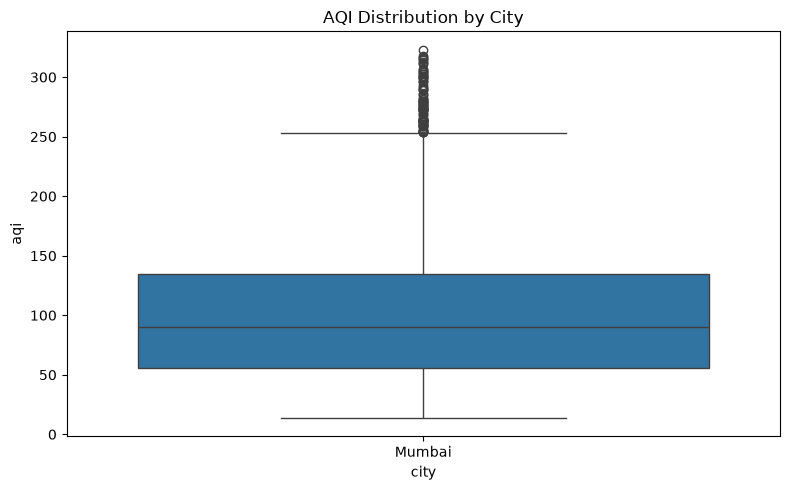

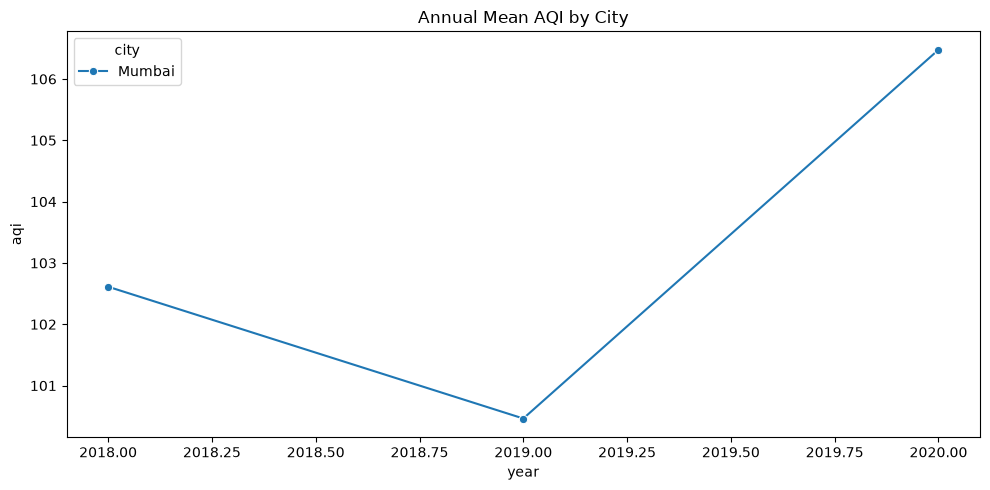

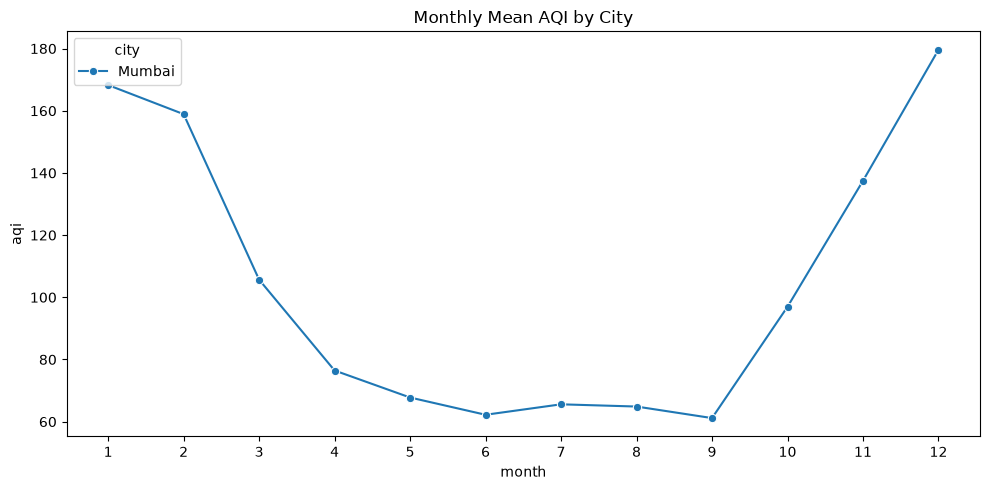

In [35]:
display(clean.groupby("city")["aqi"].agg(["count", "mean", "median", "min", "max"]).round(2))

if len(clean):
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=clean, x="city", y="aqi")
    plt.title("AQI Distribution by City")
    plt.tight_layout()
    plt.show()

    yearly = clean.groupby(["year", "city"], as_index=False)["aqi"].mean()
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=yearly, x="year", y="aqi", hue="city", marker="o")
    plt.title("Annual Mean AQI by City")
    plt.tight_layout()
    plt.show()

    monthly = clean.groupby(["month", "city"], as_index=False)["aqi"].mean()
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=monthly, x="month", y="aqi", hue="city", marker="o")
    plt.title("Monthly Mean AQI by City")
    plt.xticks(range(1, 13))
    plt.tight_layout()
    plt.show()


## 9. Train Random Forest Regression

Predictors are pollutant measurements. Latitude and longitude are used for geographic selection and Power BI mapping, **not** as ML predictors. The model uses a chronological 80/20 split and imputes missing predictors using training data only.

Because the supplied Kaggle files have no Navi Mumbai observations, the current model will be trained on Mumbai observations only. Do not interpret its scores as a two-city model.

In [36]:
if not pollutant_cols:
    raise ValueError("No pollutant columns found for modelling.")

model_data = clean.sort_values("date").reset_index(drop=True).copy()
split_at = int(len(model_data) * 0.80)
if split_at < 2 or len(model_data) - split_at < 1:
    raise ValueError("Not enough rows to create a chronological 80/20 split.")

train_df = model_data.iloc[:split_at].copy()
test_df = model_data.iloc[split_at:].copy()

# Keep only pollutant columns with at least one observed value in the training period.
# SimpleImputer may otherwise drop all-empty columns, causing feature-importance length mismatches.
model_feature_cols = [
    col for col in pollutant_cols
    if train_df[col].notna().any()
]
dropped_empty_features = sorted(set(pollutant_cols) - set(model_feature_cols))
if dropped_empty_features:
    print("Excluding pollutant columns that are entirely missing in the training set:",
          dropped_empty_features)
if not model_feature_cols:
    raise ValueError("No pollutant features have observed values in the training set.")

X_train = train_df[model_feature_cols]
y_train = train_df["aqi"]
X_test = test_df[model_feature_cols]
y_test = test_df["aqi"]

model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred) if len(y_test) > 1 else np.nan

metrics = pd.DataFrame([
    {"Metric": "MAE", "Value": mae},
    {"Metric": "RMSE", "Value": rmse},
    {"Metric": "R2", "Value": r2},
    {"Metric": "Training_Rows", "Value": len(train_df)},
    {"Metric": "Test_Rows", "Value": len(test_df)},
    {"Metric": "Model_Feature_Count", "Value": len(model_feature_cols)},
    {"Metric": "Navi_Mumbai_Observation_Rows", "Value": int((clean["city"].str.lower() == "navi mumbai").sum())}
])
display(metrics)
metrics.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False)


Excluding pollutant columns that are entirely missing in the training set: ['toluene', 'xylene']


,Metric,Value
0,MAE,8.052122
1,RMSE,12.269615
2,R2,0.738496
3,Training_Rows,3097.000000
4,Test_Rows,775.000000
5,Model_Feature_Count,10.000000
6,Navi_Mumbai_Observation_Rows,0.000000


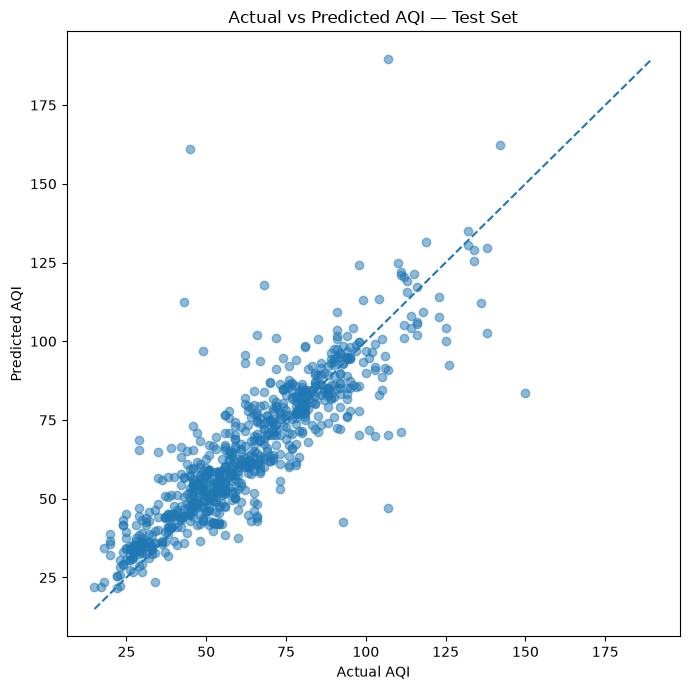

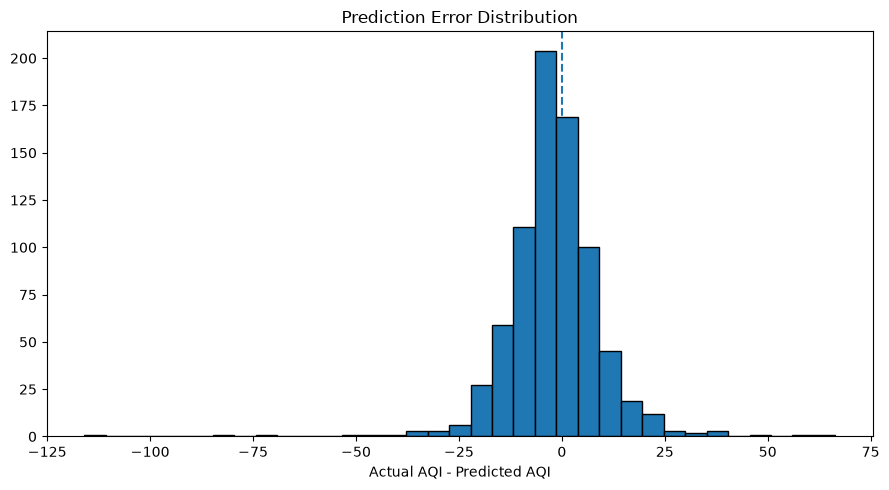

,Feature,Importance
1,pm10,0.700886
0,pm2_5,0.180436
4,nox,0.044513
6,co,0.030477
2,no,0.009622
8,o3,0.008590
3,no2,0.007105
5,nh3,0.006653
9,benzene,0.006622
7,so2,0.005096


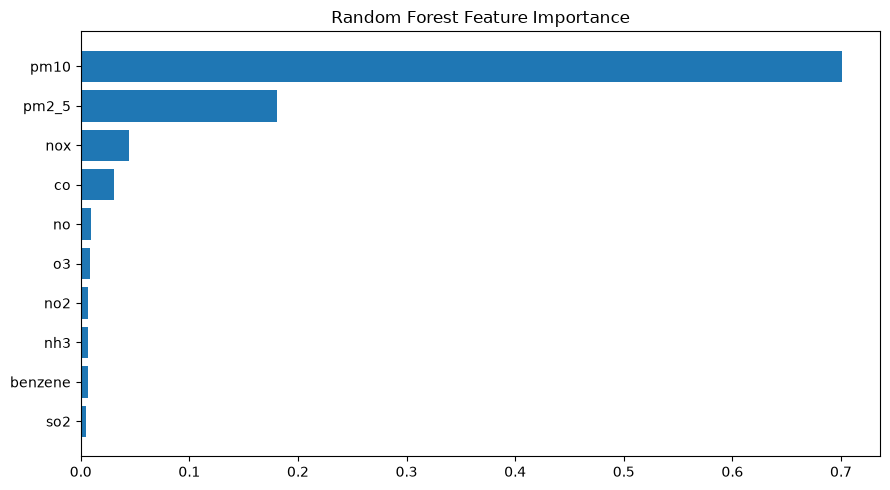

In [37]:
# Actual vs predicted plot
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.5)
lo = min(float(y_test.min()), float(np.min(y_pred)))
hi = max(float(y_test.max()), float(np.max(y_pred)))
plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI — Test Set")
plt.tight_layout()
plt.show()

# Error distribution
errors = y_test.to_numpy() - y_pred
plt.figure(figsize=(9, 5))
plt.hist(errors, bins=35, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Actual AQI - Predicted AQI")
plt.title("Prediction Error Distribution")
plt.tight_layout()
plt.show()

rf = model.named_steps["rf"]
# Derive names from the exact columns used to fit the model. This avoids a
# ValueError if preprocessing removes columns that were entirely missing.
feature_importances = np.asarray(rf.feature_importances_).ravel()
if len(model_feature_cols) != len(feature_importances):
    raise ValueError(
        f"Feature-name/importance mismatch: {len(model_feature_cols)} names "
        f"but {len(feature_importances)} importances. "
        "Check preprocessing and training feature columns."
    )
importance = pd.DataFrame({
    "Feature": model_feature_cols,
    "Importance": feature_importances
}).sort_values("Importance", ascending=False)
display(importance)
importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"][::-1], importance["Importance"][::-1])
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


## 10. Export Power BI-ready CSV with predictions

In [38]:
powerbi = model_data.copy()
powerbi["predicted_aqi"] = np.nan
powerbi["prediction_error"] = np.nan
powerbi["absolute_error"] = np.nan
powerbi["residual"] = np.nan
powerbi["predicted_aqi_category"] = pd.Series(index=powerbi.index, dtype="object")
powerbi["model_split"] = "Train"

test_idx = test_df.index
powerbi.loc[test_idx, "predicted_aqi"] = y_pred
powerbi.loc[test_idx, "prediction_error"] = test_df["aqi"].to_numpy() - y_pred
powerbi.loc[test_idx, "absolute_error"] = np.abs(test_df["aqi"].to_numpy() - y_pred)
powerbi.loc[test_idx, "residual"] = test_df["aqi"].to_numpy() - y_pred
powerbi.loc[test_idx, "predicted_aqi_category"] = pd.Series(
    [aqi_category(v) for v in y_pred], index=test_idx, dtype="object"
)
powerbi.loc[test_idx, "model_split"] = "Test"

# Keep category columns explicitly string/object typed for pandas 3.x compatibility.

powerbi_file = OUTPUT_DIR / "mumbai_navi_mumbai_aqi_powerbi.csv"
powerbi.to_csv(powerbi_file, index=False)

# City/station coverage report is important for documenting the data limitation.
coverage_all.to_csv(OUTPUT_DIR / "station_coverage_report.csv", index=False)

print("Saved files:")
for f in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", f.resolve())
print("\nPower BI rows/columns:", powerbi.shape)
display(powerbi.head())


Saved files:
- C:\Users\Shubham\Desktop\My Works\DV Mini Project\aqi_outputs\feature_importance.csv
- C:\Users\Shubham\Desktop\My Works\DV Mini Project\aqi_outputs\model_metrics.csv
- C:\Users\Shubham\Desktop\My Works\DV Mini Project\aqi_outputs\mumbai_navi_mumbai_aqi_powerbi.csv
- C:\Users\Shubham\Desktop\My Works\DV Mini Project\aqi_outputs\mumbai_navi_mumbai_geocoded_before_cleaning.csv
- C:\Users\Shubham\Desktop\My Works\DV Mini Project\aqi_outputs\station_coverage_report.csv

Power BI rows/columns: (3872, 42)


,stationid,date,pm2_5,pm10,no,no2,nox,nh3,co,so2,o3,benzene,toluene,xylene,aqi,aqi_bucket,stationname,city,state,status,stationname_coordinate,city_coordinate,latitude,longitude,coordinate_notes,coordinate_source_type,_merge,year,month,month_name,quarter,day_of_week,day_name,weekend,season,aqi_category,predicted_aqi,prediction_error,absolute_error,residual,predicted_aqi_category,model_split
0,MH005,2018-05-07,18.44,NaN,23.53,22.60,46.03,NaN,1.30,22.00,34.00,0.29,NaN,NaN,73.0,Satisfactory,"Bandra, Mumbai - MPCB",Mumbai,Maharashtra,Active,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,Published coordinates for Bandra CAAQMS; match...,MPCB report coordinates,both,2018,5,May,2,0,Monday,0,Summer,Satisfactory,NaN,NaN,NaN,NaN,NaN,Train
1,MH005,2018-05-08,18.07,48.80,34.20,29.98,64.12,NaN,1.36,19.58,35.44,0.35,NaN,NaN,82.0,Satisfactory,"Bandra, Mumbai - MPCB",Mumbai,Maharashtra,Active,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,Published coordinates for Bandra CAAQMS; match...,MPCB report coordinates,both,2018,5,May,2,1,Tuesday,0,Summer,Satisfactory,NaN,NaN,NaN,NaN,NaN,Train
2,MH005,2018-05-09,18.55,62.07,34.50,28.90,63.40,NaN,1.35,18.59,35.91,0.44,NaN,NaN,84.0,Satisfactory,"Bandra, Mumbai - MPCB",Mumbai,Maharashtra,Active,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,Published coordinates for Bandra CAAQMS; match...,MPCB report coordinates,both,2018,5,May,2,2,Wednesday,0,Summer,Satisfactory,NaN,NaN,NaN,NaN,NaN,Train
3,MH005,2018-05-10,22.57,67.03,22.38,23.46,45.81,NaN,1.30,21.30,37.26,0.32,NaN,NaN,77.0,Satisfactory,"Bandra, Mumbai - MPCB",Mumbai,Maharashtra,Active,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,Published coordinates for Bandra CAAQMS; match...,MPCB report coordinates,both,2018,5,May,2,3,Thursday,0,Summer,Satisfactory,NaN,NaN,NaN,NaN,NaN,Train
4,MH005,2018-05-11,23.57,71.80,21.08,25.71,46.80,NaN,1.26,24.83,36.59,0.44,NaN,NaN,73.0,Satisfactory,"Bandra, Mumbai - MPCB",Mumbai,Maharashtra,Active,"Bandra, Mumbai - MPCB",Mumbai,19.063083,72.846444,Published coordinates for Bandra CAAQMS; match...,MPCB report coordinates,both,2018,5,May,2,4,Friday,0,Summer,Satisfactory,NaN,NaN,NaN,NaN,NaN,Train
